# CAES Mini-Project: Variant 1b System Design and Simulation

Compressed Air Energy Storage (CAES) stores electricity during off-peak hours by compressing ambient air into a storage reservoir. During discharge, the compressed air is extracted, heated via a combustor, and expanded through a turbine to generate electricity. 

## Variant 1b Description

**Variant 1b** models a single-stage, non-adiabatic CAES plant with a constant-pressure reservoir:

* **Charge:** Ambient air is compressed in a single-stage compressor directly to the storage pressure $P_{\text{max}}$. The heat of compression is removed via a water cooler and rejected to ambient (no thermal storage), bringing the air towards ambient temperature before storage.

* **Discharge:** Air leaves the store at a constant inlet pressure of 16 bar (quasi-steady expansion). A fuel combustor heats the air from near ambient conditions up to the turbine inlet temperature ($550^\circ\text{C}$) before it expands across a single turbine stage to ambient pressure.

## System Specifications & Given Parameters

| Category | Parameter | Symbol | Value | Unit / Description |
|---|---|---|---|---|
| **Fluid Properties** | Working fluid | — | Air | Real-gas properties via CoolProp (`"Air"`) |
| **Ambient Conditions** | Ambient temperature | $T_0$ | 15 (288.15) | °C (K) |
| | Ambient pressure | $P_0$ | 1.013 | bar (compressor inlet / turbine exhaust) |
| **Storage Conditions** | Storage / max pressure | $P_{\text{max}}$ | 16 | bar (held constant during operation) |
| | Reservoir thermal state | $T_{\text{res}}$ | 15 (288.15) | °C (assumed returns and remains at $T_0$) |
| **Operating Targets** | Discharge shaft power | $P_{\text{shaft}}$ | 1 | MW |
| | Discharge duration | $\Delta t_{\text{dis}}$ | 4 | h (delivers 4 MWh per cycle) |
| | Charge duration | $\Delta t_{\text{ch}}$ | 4 | h (governs charge mass flow rate) |
| **Component Efficiencies** | Compressor isentropic efficiency | $\eta_{\text{is,c}}$ | 0.85 | Single stage |
| | Turbine isentropic efficiency | $\eta_{\text{is,t}}$ | 0.88 | Single stage |
| | Mechanical / generator efficiency | $\eta_{\text{mech}}$ | 0.98 | Shaft transmission / generator conversion |
| **Thermal Parameters** | Cooler pinch | $\Delta T_{\text{pinch}}$ | 10 | K (air cooled towards $T_0 + 10\text{ K}$) |
| | Turbine inlet temperature | TIT | 550 (823.15) | °C (K), achieved via direct heat addition |
| | Reference fuel-to-electricity efficiency | $\eta_f$ | 0.40 | Metric weighting factor for fuel input |

## Design and Simulation Tasks

The project workflow for Variant 1b consists of two phases:

1. **Design Mode:**
   * Size the single-stage compressor and turbine for the specified 1 MW / 4 h delivery target.
   * Size the water cooler heat-exchanger area ($A$) based on the aftercooling duty and 10 K pinch.
   * Size the required constant-pressure storage volume ($V$) needed to store the total cycle air mass.

2. **Simulation Mode:**
   * Simulate a full charge and discharge cycle under quasi-steady constant-pressure operation.
   * Compute the overall round-trip efficiency ($\eta$), where fuel is converted to its electrical equivalent:
     $$\eta = \frac{W_{\text{turbine}}}{W_{\text{compressor}} + \eta_f \cdot Q_{\text{combustion}}}, \qquad \eta_f = 0.40$$
   * Evaluate the energy balance, the electrical vs. fuel input split ($W_{\text{compressor}}$ vs. $Q_{\text{combustion}}$), and the peak compressor discharge temperature.
   * Provide at least one quantified performance improvement proposal and benchmark the storage volume and efficiency against the sliding-pressure variant (1a).

Here are some sources i used to return to later (soso)

Return to Gas Turbines EENG4 S8 for compressor eq and details (soso)

Paper on which sile will the pinch temp be occuring based on the Cc and Ch (LMTD) method. https://sci-hub.fr/10.1016/B978-008042839-0/50008-2 (soso)

Also return to EENG3 S6 Lec 4 for counter flow details and eq (soso)

The following section defines the imports used in the code

In [70]:
# --- imports ---
from pathlib import Path
import sys

import numpy as np
from CoolProp.CoolProp import PropsSI

import caldis
from caldis.core.system import System
from caldis.components import FluidBoundary, Compressor, SizingHX, CombustionChamber, Turbine
from caldis.components.vessels.tank import TankConstP

from caldis.fluids import CoolPropBackend

from caldis.solvers import dynamic, solve, simulate
#from caldis.solvers import solve, simulate

    
print("Caldis OK", caldis.__version__)


Caldis OK 0.4.0


## Parameters

In [71]:
# ==============================================================================
# 1. Given in the Document (Specification)
# ==============================================================================

# Fluid property backends
be_air = CoolPropBackend("Air")
be_fuel = CoolPropBackend("Methane")
be_water = CoolPropBackend("Water")


# Reference ambient conditions
T0 = 15.0 + 273.15           # [K] Ambient temperature
Tpinch = 10                  # [K] Ambient temperature
P0 = 1.013e5                 # [Pa] Ambient pressure

# Operational targets
W_target = 1.0e6             # [W] Turbine net shaft power (1 MW target)
t_discharge = 4.0 * 3600.0   # [s] Discharge duration (4 h -> 4 MWh)
t_charge = 4.0 * 3600.0      # [s] Charge duration (4 h)

# Cycle and storage operating limits
Pmax = 16.0e5                # [Pa] Storage pressure (constant pressure)
Ttit = 550.0 + 273.15        # [K] Turbine inlet temperature
T_pinch = 10.0               # [K] Cooler pinch temperature difference

# Component efficiencies
Eta_ISC = 0.85               # Compressor isentropic efficiency
Eta_IST = 0.88               # Turbine isentropic efficiency
Eta_Mech = 0.98              # Mechanical / generator efficiency
Eta_Fuel = 0.40              # Fuel-to-electricity reference efficiency

In [72]:
# ==============================================================================
# Derived Thermo dynamic properties
# ==============================================================================

# Tank Properties
h_tank_charge = PropsSI("H", "T", T0 + T_pinch, "P", Pmax, "Air")           # [J/kg] Stored air enthalpy
h_tank_discharge = PropsSI("H", "T", T0, "P", Pmax, "Air")        # [J/kg] Stored air enthalpy

rho_tank_Air_discharge = PropsSI("D", "T", T0, "P", Pmax, "Air")  # [kg/m³] Stored air density

# Turbine Properties
P_turb_in = Pmax * (1.0 - 0.04)                                   # [Pa] 15.36 bar                                           
h_turb_in = PropsSI("H", "T", Ttit, "P", P_turb_in , "Air")       # [J/kg]
s_turb_in = PropsSI("S", "T", Ttit, "P", P_turb_in, "Air")        # [J/(kg·K)]
h_turb_out_s = PropsSI("H", "P", P0, "S", s_turb_in, "Air")       # [J/kg]

In [73]:
# ==============================================================================
# Sizing Parameters for Heat Exchanger (Aftercooler)
# ==============================================================================

# Cooling water inlet and operating states
T_water_in = T0              # [K] Cooling water inlet temperature
P_water_in = P0              # [Pa] Cooling water inlet pressure
T_water_out_guess = 100.0 + 273.15  # [K] Water outlet temperature initial guess

# Convection film heat transfer coefficients
h_film_air = 100.0           # [W/(m²·K)] Air-side film coefficient
h_film_water = 3000.0        # [W/(m²·K)] Water-side film coefficient

# Geometric configuration
Ratio_Area_cold_to_hot = 0.5 # Cold-side to hot-side heat transfer area ratio

In [74]:
# ==============================================================================
# Flowrate Calculations
# ==============================================================================

# Net specific work delivered at shaft
w_sp = Eta_Mech * Eta_IST * (h_turb_in - h_turb_out_s)          # [J/kg]

# Required mass flow rates during charge and discharge
Mdot_discharge = W_target / w_sp                                # [kg/s] Air discharge flow rate
Mass_total = Mdot_discharge * t_discharge                       # [kg] Total air mass required
Mdot_charge = Mass_total / t_charge    

# Guess Estimation of fuel flowrate
Mdot_fuel = 0.286


In [75]:
# ==============================================================================
# Sizing for Tank Volume (Cylinder — Stainless Steel 304)
# ==============================================================================

# Required reservoir volume 
V_tank_initial = (Mass_total / rho_tank_Air_discharge)            # [m³] Initial storage volume

# Material properties: Stainless Steel 304
Density_Steel_304 = 7955.0   # [kg/m³]
Cp_Tank = 500.0              # [J/(kg·K)]
k_steel = 16.0               # [W/(m·K)] Thermal conductivity

# Cylinder vessel dimensions
Diameter_Tank_out = 8.0      # [m] Outer diameter
Thickness_wall = 0.12        # [m] Wall thickness

r_out = Diameter_Tank_out / 2.0             # [m] Outer radius
r_in = r_out - Thickness_wall               # [m] Inner radius
r_mid = (r_out + r_in) / 2.0                # [m] Mid-wall radius

# Cylinder geometric sizing
Area_Tank_in_cs = np.pi * (r_in ** 2)                  # [m²] Inner cross-sectional area
Area_Tank_Shell_cs = np.pi * (r_out ** 2 - r_in ** 2)  # [m²] Annular shell cross section
Length_Tank = V_tank_initial / Area_Tank_in_cs         # [m] Cylinder length

Area_Tank_in_surf = 2.0 * np.pi * r_in * Length_Tank   # [m²] Internal convective surface area
Volume_Tank_Shell = Area_Tank_Shell_cs * Length_Tank  # [m³] Metal shell volume
Mass_Tank = Density_Steel_304 * Volume_Tank_Shell      # [kg] Total vessel shell mass

# Wall thermal capacitance
Cwall = Mass_Tank * Cp_Tank                            # [J/K] Wall heat capacity

# Thermal conductance between wall and fluid
h_in = 50.0                                            # [W/(m²·K)] Internal convection coefficient
R_conv_in = 1.0 / (h_in * Area_Tank_in_surf)           # [K/W] Convective resistance
R_wall_inner = np.log(r_mid / r_in) / (2.0 * np.pi * k_steel * Length_Tank)  # [K/W] Conduction
UA_wall = 1.0 / (R_conv_in + R_wall_inner)             # [W/K] Wall-to-fluid thermal conductance

# Heat replenishment rate to offset constant-pressure volume contraction cooling
#Q_boundary_work = Mdot_discharge * (Pmax / rho_tank)   # [W] Expansion boundary heat rate


## Charge Phase
| Step | Component | Flow / Working Fluid | Energy / Secondary Streams |
|:---:|:---|:---|:---|
| **1** | **Ambient Intake** | Air at ambient ($T_0 = 15^\circ\text{C},\; P_0 = 1.013\text{ bar}$) | — |
| | $\Downarrow$ | *Suction line* | |
| **2** | **Compressor** | Single-stage compression $\rightarrow P_{\text{max}} = 16\text{ bar}$ | $\longleftarrow$ **Compressor work (elec. in)** |
| | $\Downarrow$ | *Hot compressed air* | |
| **3** | **Cooler (water)** | Cooled to $T_0 + 10\text{ K} = 25^\circ\text{C}$ | $\longrightarrow$ **Rejected heat (not recovered)** |
| | $\Downarrow$ | *Cooled air at $16\text{ bar}$* | |

In [76]:
'''# --- Component setup ---
Source_Charge     = FluidBoundary(name="Source", p=P0, T=T0, h=None, mdot=-Mdot_charge, backend=be_air)
Comp_Charge       = Compressor(name="Comp", backend=be_air, eta_is=Eta_ISC)

# Since Ch<Cc in a counter flow heat exchanger, the pinch point is on the cold side.
# As the outlet of the heat exchanger was set to be T0 + 10, 
# Then the inlet of the water on the cold side would be T0 + 10 - Tpinch= T0
# Pressure is assumed to be atm as it does not affect the heat transfer
Water_Cold_Charge = FluidBoundary(name="Water_Cold", p=P0, T=T0, h=None, mdot=-Mdot_charge, backend=be_water)
Water_Hot_Charge  = FluidBoundary(name="Water_Hot",  p=None, T=None, h=None, mdot=None, backend=be_water)

# The area ratio of the heat exchanger is set to 0.5, 
# meaning that the area of the cold side is half of the area of the hot side. 
# This is a reasonable assumption for a counter flow heat exchanger.
# hfilm defined in A3
Hex_Charge = SizingHX(name="Hex", backend_hot=be_air, backend_cold=be_water, h_hot=h_film_air, h_cold=h_film_water, area_ratio_cold_to_hot=Ratio_Area_cold_to_hot)
Tank_Charge = TankConstP(name="Tank", backend=be_air, p=Pmax, h_init=h_tank_discharge, V_init=20, C_wall=Cwall, T_wall_init=T0, UA_wall=UA_wall, Q_heater=0)

Closed_Outlet = FluidBoundary(name="Closed_Out", mdot=0.0, backend=be_air)  # No discharge during charge''
'''

'# --- Component setup ---\nSource_Charge     = FluidBoundary(name="Source", p=P0, T=T0, h=None, mdot=-Mdot_charge, backend=be_air)\nComp_Charge       = Compressor(name="Comp", backend=be_air, eta_is=Eta_ISC)\n\n# Since Ch<Cc in a counter flow heat exchanger, the pinch point is on the cold side.\n# As the outlet of the heat exchanger was set to be T0 + 10, \n# Then the inlet of the water on the cold side would be T0 + 10 - Tpinch= T0\n# Pressure is assumed to be atm as it does not affect the heat transfer\nWater_Cold_Charge = FluidBoundary(name="Water_Cold", p=P0, T=T0, h=None, mdot=-Mdot_charge, backend=be_water)\nWater_Hot_Charge  = FluidBoundary(name="Water_Hot",  p=None, T=None, h=None, mdot=None, backend=be_water)\n\n# The area ratio of the heat exchanger is set to 0.5, \n# meaning that the area of the cold side is half of the area of the hot side. \n# This is a reasonable assumption for a counter flow heat exchanger.\n# hfilm defined in A3\nHex_Charge = SizingHX(name="Hex", backe

In [ ]:
# ==============================================================================
# Charge Subsystem Component Definitions
# ==============================================================================

# Cooling water mass flow rate (keeps water temperature safe at ~55 °C)
Mdot_water = 6.0  # [kg/s]

# 1. Steady-state Charge Design Components (Compressor & Cooler Sizing)
Source_Charge = FluidBoundary(name="Source_Charge", p=P0, T=T0, mdot=-Mdot_charge, backend=be_air)

Comp_Charge = Compressor(name="Comp_Charge", backend=be_air, eta_is=Eta_ISC)

Water_Cold_Charge = FluidBoundary(name="Water_Cold", p=P0, T=T0, mdot=-Mdot_water, backend=be_water)

Water_Hot_Charge = FluidBoundary(name="Water_Hot", backend=be_water)

Hex_Charge = SizingHX(
    name="Hex_Charge",
    backend_hot=be_air,
    backend_cold=be_water,
    h_hot=h_film_air,
    h_cold=h_film_water,
    area_ratio_cold_to_hot=Ratio_Area_cold_to_hot
)

#Cooled_Air_Sink = FluidBoundary(name="Cooled_Sink", p=Pmax, T=T0 + T_pinch, backend=be_air)

# 2. Dynamic Tank Charge Components (Filling the Tank over 4 Hours)
#ir_from_Cooler = FluidBoundary(name="Air_Inflow", T=T0 + T_pinch, mdot=-Mdot_charge, backend=be_air)

Tank_Charge = TankConstP(
    name="Tank_Charge",
    backend=be_air,
    p=Pmax,
    h_init=h_tank_charge,
    V_init=20,              # [m³] Minimum reserve volume at start of charge
    C_wall=Cwall,
    T_wall_init=T0,
    UA_wall=UA_wall,
    Q_heater=0.0
)
Closed_Outlet_Charge = FluidBoundary(name="Sink", p=None, T=None, h=None, mdot=0.0, backend=be_air)

In [ ]:
# --- System wiring & start points ---
sys_ = System("Comp_Parts")
sys_.add(Source_Charge, Comp_Charge, Hex_Charge, Water_Cold_Charge, Water_Hot_Charge, Tank_Charge, Closed_Outlet_Charge)

sys_.connect(Source_Charge.port,     Comp_Charge.inl)

sys_.connect(Comp_Charge.out,        Hex_Charge.hot_in)

sys_.connect(Water_Cold_Charge.port, Hex_Charge.cold_in)
sys_.connect(Water_Hot_Charge.port,  Hex_Charge.cold_out)

sys_.connect(Hex_Charge.hot_out, Tank_Charge.inl)
sys_.connect(Tank_Charge.out, Closed_Outlet_Charge.port) 

# Dimensionnement instantané : le cooler doit fournir de l'air à 25 °C
sys_.add_constraint(
    lambda: be_air.T(Hex_Charge.hot_out.p, Hex_Charge.hot_out.h) - T_air_to_tank,
    name="cooler_outlet_temperature",
)

# Start-point gives the solver a physically sensible initial guess.
# Initially when we calculated the output temp in the 1st step we got 410°C
# The compressor outlet T here isn't known yet, but ~400°C is a good guess 

sys_.set_start_port(Comp_Charge.inl,    p=P0,   T=T0,          mdot= Mdot_charge)
sys_.set_start_port(Comp_Charge.out,    p=Pmax, T=T_out_comp_guess,   mdot=-Mdot_charge)
sys_.set_start_port(Hex_Charge.hot_in,  p=Pmax, T=T_out_comp_guess,   mdot=Mdot_charge)
sys_.set_start_port(Hex_Charge.hot_out, p=Pmax, T=T0 + Tpinch,    mdot= -Mdot_charge)
sys_.set_start_port(Tank_Charge.inl,    p=Pmax, T=T_air_to_tank,    mdot=Mdot_charge)
sys_.set_start_port(Tank_Charge.out,    p=Pmax, T=T_tank_initial,    mdot=0.0)

# Water side
sys_.set_start_port(Hex_Charge.cold_in,  p=P0, T=T0,           mdot= Mdot_water)
sys_.set_start_port(Hex_Charge.cold_out, p=P0, T=T_water_out_Guess,   mdot= -Mdot_water)

sys_.init_starts()

# --- Run 4-Hour Dynamic Simulation ---
results = simulate(sys_, t_end=4 * 3600, dt=240, init="consistent", progress=True)

# --- Inspect Results ---
df = results.to_dataframe()


# --- Final Results ---
m_tank_initial_sim = df["Tank_Charge.fluid.M"].iloc[0]
m_tank_final_sim = df["Tank_Charge.fluid.M"].iloc[-1]
m_air_added_sim = m_tank_final_sim - m_tank_initial_sim

V_tank_initial_sim = df["Tank_Charge.V"].iloc[0]
V_tank_final_sim = df["Tank_Charge.V"].iloc[-1]
T_tank_final_sim = df["Tank_Charge.T_fluid"].iloc[-1]
P_tank_final = df["Tank_Charge.fluid.inl.p"].iloc[-1]

# We change the sign to display a positive absorbed power.
Wdot_comp = -df["Comp_Charge.Wdot"].to_numpy()

# Temporal integration of the power in kWh
E_comp_kWh = np.trapz(Wdot_comp, results.time) / 3.6e6


print("\n--- Final Results ---")
print(f"Time charged            : {results.time[-1] / 3600:.2f} h")
print(f"Charge flow rate     : {Mdot_charge:.5f} kg/s")
print(f"Air mass added to tank     : {m_air_added_sim:.1f} kg")
print(f"Initial residual mass : {m_tank_initial_sim:.1f} kg")
print(f"Final mass in tank : {m_tank_final_sim:.1f} kg")
print(f"Initial tank volume    : {V_tank_initial_sim:.1f} m3")

print(f"Final Volume after charge    : {V_tank_final_sim:.1f} m3")
print(f"Final Temperature after charge: {T_tank_final_sim - 273.15:.2f} °C")
print(f"Final Pressure in Tank   : {P_tank_final / 1e5:.2f} bar")
print(f"Initial Compressor Power : {Wdot_comp[0] / 1e6:.3f} MW")
print(f"Compressor Energy over 4 h      : {E_comp_kWh / 1000:.3f} MWh")


In [ ]:
'''
# ==============================================================================
# Part A: Steady-State Charge Design (Compressor & Cooler Sizing)
# ==============================================================================
sys_charge_design = System("Charge_Design")
sys_charge_design.add(Source_Charge, Comp_Charge, Hex_Charge, Water_Cold_Charge, Water_Hot_Charge, Cooled_Air_Sink)

# Connections
sys_charge_design.connect(Source_Charge.port,     Comp_Charge.inl)
sys_charge_design.connect(Comp_Charge.out,        Hex_Charge.hot_in)
sys_charge_design.connect(Hex_Charge.hot_out,     Cooled_Air_Sink.port)
sys_charge_design.connect(Water_Cold_Charge.port, Hex_Charge.cold_in)
sys_charge_design.connect(Hex_Charge.cold_out,    Water_Hot_Charge.port)

# Starting points
sys_charge_design.set_start_port(Comp_Charge.inl,     p=P0,   T=T0,                 mdot= Mdot_charge)
sys_charge_design.set_start_port(Comp_Charge.out,     p=Pmax, T=410.0 + 273.15,     mdot=-Mdot_charge)
sys_charge_design.set_start_port(Hex_Charge.hot_in,   p=Pmax, T=410.0 + 273.15,     mdot= Mdot_charge)
sys_charge_design.set_start_port(Hex_Charge.hot_out,  p=Pmax, T=T0 + T_pinch,       mdot=-Mdot_charge)
sys_charge_design.set_start_port(Hex_Charge.cold_in,  p=P0,   T=T0,                 mdot= Mdot_water)
sys_charge_design.set_start_port(Hex_Charge.cold_out, p=P0,   T=T0 + 40.0,          mdot=-Mdot_water)
sys_charge_design.init_starts()

# Solve steady-state sizing
sol_charge = solve(sys_charge_design)

Wdot_comp = Comp_Charge.inl.mdot * (Comp_Charge.out.h - Comp_Charge.inl.h)  # [W]
W_comp_total = Wdot_comp * t_charge                                        # [J]


# ==============================================================================
# Part B: Dynamic Tank Filling Simulation (4 Hours)
# ==============================================================================
sys_charge_dyn = System("Charge_Dynamic")
sys_charge_dyn.add(Cooled_Air_Sink, Tank_Charge, Closed_Outlet_Charge)

sys_charge_dyn.connect(Cooled_Air_Sink.port, Tank_Charge.inl)
sys_charge_dyn.connect(Tank_Charge.out,      Closed_Outlet_Charge.port)

sys_charge_dyn.set_start_port(Cooled_Air_Sink.port, p=Pmax, T=T0 + T_pinch, mdot=-Mdot_charge)
sys_charge_dyn.set_start_port(Tank_Charge.inl,          p=Pmax, T=T0 + T_pinch, mdot= Mdot_charge)
sys_charge_dyn.set_start_port(Tank_Charge.out,          p=Pmax, T=T0 + T_pinch, mdot= 0.0)
sys_charge_dyn.set_start_port(Closed_Outlet_Charge.port, p=Pmax, T=T0 + T_pinch, mdot= 0.0)
sys_charge_dyn.init_starts()

results_charge = simulate(sys_charge_dyn, t_end=t_charge, dt=240, init="consistent", progress=True)

df_charge = results_charge.to_dataframe()
V_charged = df_charge["Tank_Charge.V"].iloc[-1]
'''

  

✓ DOF: square (32 unknowns)
✓ start point: evaluable
  direct Newton: ok (5 it, |F_scaled|=1.5e-09)
✓ SOLVED (|F_scaled|=1.5e-09)
✓ DOF: square (17 unknowns)
✓ start point: evaluable


RuntimeError: Pas t=240s : jacobienne singulière (it 1)

## Discharge Phase
| Step | Reservoir | Flow / Working Fluid | Energy / Secondary Streams |
|:---:|:---|:---|:---|
| | $\Downarrow$ | *Extraction line (constant inlet pressure $16\text{ bar}$)* | |
| **1** | **Combustor** | Direct heat addition up to $\text{TIT} = 550^\circ\text{C}$ | $\longleftarrow$ **Fuel heat input ($Q$)** |
| | $\Downarrow$ | *High-pressure hot gas at $16\text{ bar},\; 550^\circ\text{C}$* | |
| **2** | **Turbine** | Single-stage expansion down to ambient ($P_0$) | $\longrightarrow$ **Turbine work (elec. out: 1 MW)** |
| | $\Downarrow$ | *Exhaust gas* | |
| **3** | **Exhaust** | Discharged to ambient atmosphere ($P_0$) | — |

In [ ]:
# --- Discharge Cycle ---
Source = FluidBoundary(name="Source", T=T0, mdot=0, backend=be_air)
Tank = TankConstP(name="Tank", backend=be_air, p=Pmax, h_init=h_tank_discharge, V_init=V_charged, C_wall=Cwall, T_wall_init=T0, UA_wall=UA_wall, Q_heater=0)
Comb = CombustionChamber(name="Comb", backend_air=be_air, backend_fuel=be_fuel, LHV=50e6, eta_comb=1.0, dp_rel=0.04)
Fuel_in = FluidBoundary(name="Fuel_in", p=P0, T=T0, backend=be_fuel)
Turbine = Turbine(name="Turbine", backend=be_air, eta_is=Eta_IST, eta_mech=Eta_Mech)
Exhaust = FluidBoundary(name="Exhaust", p=P0, backend=be_air)

In [ ]:
# --- System wiring ---
sys_ = System("Discharge_Cycle")
sys_.add(Source, Tank, Turbine, Comb, Fuel_in, Exhaust)

sys_.connect(Source.port,  Tank.inl)
sys_.connect(Tank.out,     Comb.air_in)
sys_.connect(Fuel_in.port, Comb.fuel_in)
sys_.connect(Comb.gas_out, Turbine.inl)
sys_.connect(Turbine.out,  Exhaust.port)

# --- Constraints ---
# 1. Combustor reaches TIT = 550°C
sys_.add_constraint(lambda: be_air.T(Comb.gas_out.p, Comb.gas_out.h) - Ttit, "TIT_550C")

# 2. Turbine delivers 1 MW net shaft power
sys_.add_constraint(lambda: Eta_Mech * Turbine.inl.mdot * (Turbine.inl.h - Turbine.out.h) - W_target, "Wdot_1MW")

# --- Start Hints ---
sys_.set_start_port(Tank.out,      p=Pmax,           T=Tank.out.T,    mdot= - Mdot_discharge)
sys_.set_start_port(Fuel_in.port,  p=P0,             T=T0,            mdot= - Mdot_fuel)
sys_.set_start_port(Comb.air_in,   p=Tank.out.p,     T=Tank.out.T,    mdot=   Mdot_discharge)
sys_.set_start_port(Comb.gas_out,  p=Comb.gas_out.p, T=Ttit,          mdot= - Mdot_discharge)
sys_.set_start_port(Turbine.inl,   p=Comb.gas_out.p, T=Ttit,          mdot=   Mdot_discharge)
sys_.set_start_port(Turbine.out,   p=P0,             T=Turbine.out.T, mdot= - Mdot_discharge)
sys_.set_start_port(Exhaust.port,  p=P0,             T=Turbine.out.T, mdot=   Mdot_discharge)
sys_.init_starts()

# --- Run 4-Hour Dynamic Simulation ---
results = simulate(sys_, t_end=t_discharge, dt=240, init="consistent", progress=True)

# --- Inspect Results ---
df = results.to_dataframe()
df_charge = results_charge.to_dataframe()
print("\n=== Discharge Simulation Finished Successfully ===")
print(f"Air mass flow rate:       {abs(df['Tank.fluid.out.mdot'].iloc[0]):.4f} kg/s")
print(f"Fuel mass flow rate:      {abs(df['Fuel_in.port.mdot'].iloc[0]):.5f} kg/s")
print(f"Turbine power delivered:  {df['Turbine.Wdot'].iloc[0]/1e6:.4f} MW")
print(f"Starting Tank Volume:     {df['Tank.V'].iloc[0]:.1f} m³")
print(f"Final Tank Volume (4h):   {df['Tank.V'].iloc[-1]:.1f} m³")

✓ DOF: square (35 unknowns)
✓ start point: evaluable
⚠ 1 start-sanity warning(s):
   - Turbine: p_out (1.01 bar) must be < p_in (1.00 bar) for expansion
  (non-blocking.)
  simulate  [  60/60]  t=14400.0s  |F|=2.4e-09

=== Discharge Simulation Finished Successfully ===
Air mass flow rate:       2.5117 kg/s
Fuel mass flow rate:      0.02864 kg/s
Turbine power delivered:  1.0000 MW
Starting Tank Volume:     1958.2 m³
Final Tank Volume (4h):   96.2 m³


,Parameter,Value,Unit
0,Compressor electrical power,1.037,MW
1,Compressor electric energy,4.147,MWh
2,Peak compressor outlet temp,410.600,°C
3,Cooler conductance (UA),10551.300,W/K
4,Cooler total area,168.820,m²
5,Cooler heat rejected,4.079,MWh
6,Required storage volume,1958.200,m³
7,Storage pressure,16.000,bar
8,Input share (charge),100.000,%


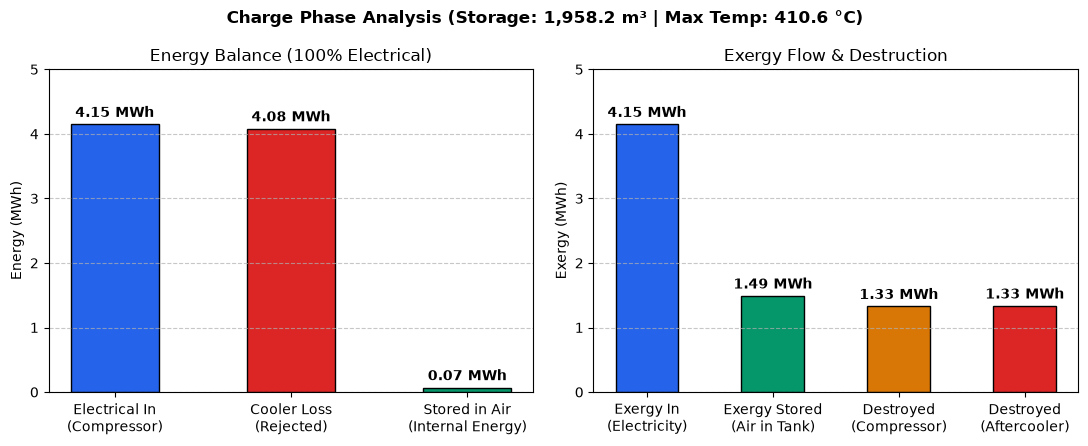

In [ ]:
# ==============================================================================
# CHARGE PHASE ANALYSIS: Table and Bar Chart
# ==============================================================================
import pandas as pd
import matplotlib.pyplot as plt

# Charge energy and metrics
charge_heat_rejected_W = Mdot_charge * (Comp_Charge.out.h - Hex_Charge.hot_out.h)
w_comp_MWh = W_comp_total / 3.6e9
q_cooler_MWh = (charge_heat_rejected_W * t_charge) / 3.6e9
t_max_comp_C = Comp_Charge.out.T - 273.15
# Table: Charge Phase Summary
charge_data = [
    ("Compressor electrical power", round(Wdot_comp / 1e6, 3), "MW"),
    ("Compressor electric energy", round(w_comp_MWh, 3), "MWh"),
    ("Peak compressor outlet temp", round(t_max_comp_C, 1), "°C"),
    ("Cooler conductance (UA)", round(Hex_Charge.UA, 1), "W/K"),
    ("Cooler total area", round(Hex_Charge.A_hot * (1.0 + Hex_Charge.params["area_ratio_cold_to_hot"]), 2), "m²"),
    ("Cooler heat rejected", round(q_cooler_MWh, 3), "MWh"),
    ("Required storage volume", round(V_charged, 1), "m³"),
    ("Storage pressure", round(Pmax / 1e5, 1), "bar"),
    ("Input share (charge)", 100.0, "%"),
]

df_charge_summary = pd.DataFrame(charge_data, columns=["Parameter", "Value", "Unit"])
display(df_charge_summary)

# Bar Chart: Charge Energy Balance & Exergy Destruction
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
fig.suptitle(f"Charge Phase Analysis (Storage: {V_charged:,.1f} m³ | Max Temp: {t_max_comp_C:.1f} °C)", fontweight="bold")

# Energy Balance
en_labels = ["Electrical In\n(Compressor)", "Cooler Loss\n(Rejected)", "Stored in Air\n(Internal Energy)"]
en_vals = [w_comp_MWh, q_cooler_MWh, w_comp_MWh - q_cooler_MWh]
bars1 = ax1.bar(en_labels, en_vals, color=["#2563eb", "#dc2626", "#059669"], edgecolor="black", width=0.5)
ax1.set_ylabel("Energy (MWh)")
ax1.set_title("Energy Balance (100% Electrical)")
ax1.set_ylim(0, 5.0)
ax1.grid(axis="y", linestyle="--", alpha=0.7)
for b in bars1:
    ax1.annotate(f"{b.get_height():.2f} MWh", xy=(b.get_x() + b.get_width()/2, b.get_height()),
                 xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontweight="bold")

# Exergy Destruction
ex_labels = ["Exergy In\n(Electricity)", "Exergy Stored\n(Air in Tank)", "Destroyed\n(Compressor)", "Destroyed\n(Aftercooler)"]
ex_vals = [w_comp_MWh, 1.488, 1.326, 1.333]
bars2 = ax2.bar(ex_labels, ex_vals, color=["#2563eb", "#059669", "#d97706", "#dc2626"], edgecolor="black", width=0.5)
ax2.set_ylabel("Exergy (MWh)")
ax2.set_title("Exergy Flow & Destruction")
ax2.set_ylim(0, 5.0)
ax2.grid(axis="y", linestyle="--", alpha=0.7)
for b in bars2:
    ax2.annotate(f"{b.get_height():.2f} MWh", xy=(b.get_x() + b.get_width()/2, b.get_height()),
                 xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontweight="bold")

fig.tight_layout()
plt.show()

,Parameter,Value,Unit
0,Turbine power delivered,1.0,MW
1,Turbine energy delivered (4 h),4.0,MWh
2,Combustion heat supplied,5.804,MWh
3,Fuel electrical equivalent,2.322,MWh
4,Turbine inlet temp (TIT),550.0,°C
5,Air discharged / Fuel consumed,"36,164 / 417.9",kg
6,Tank volume (Start -> End),"1,958.2 -> 96.2",m³
7,Overall round-trip efficiency,61.84,%
8,Electrical input share,64.1,%
9,Fuel input share,35.9,%


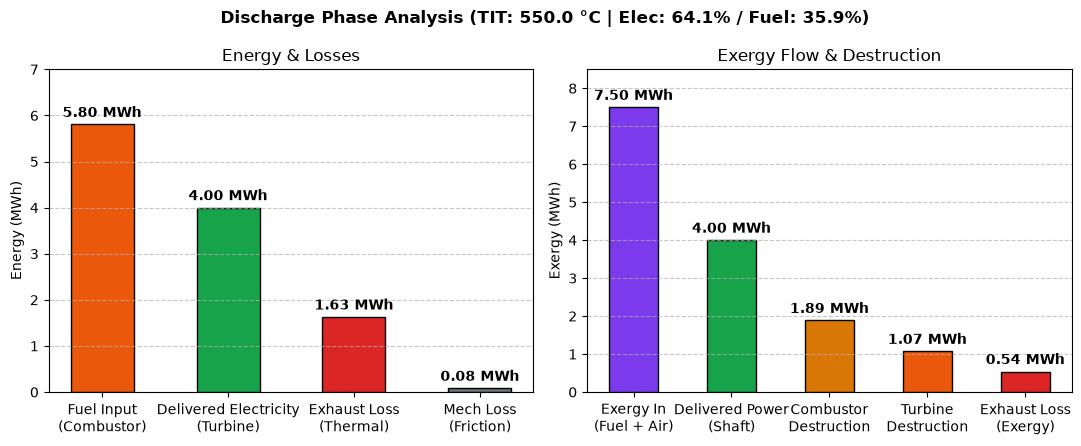

In [ ]:
# ==============================================================================
# DISCHARGE PHASE ANALYSIS: Table and Bar Chart
# ==============================================================================
import pandas as pd
import matplotlib.pyplot as plt

# Discharge energy using mean values
shaft_power_mean = df["Turbine.Wdot"].mean()
fuel_heat_mean = df["Comb.Qdot_fuel"].mean()
air_flow_mean = df["Tank.fluid.out.mdot"].abs().mean()
fuel_flow_mean = df["Fuel_in.port.mdot"].abs().mean()

turbine_energy_J = shaft_power_mean * t_discharge
fuel_energy_J = fuel_heat_mean * t_discharge
air_mass_kg = air_flow_mean * t_discharge
fuel_mass_kg = fuel_flow_mean * t_discharge

w_turb_MWh = turbine_energy_J / 3.6e9
q_fuel_MWh = fuel_energy_J / 3.6e9
fuel_electric_equivalent_J = Eta_Fuel * fuel_energy_J
weighted_input_J = W_comp_total + fuel_electric_equivalent_J
round_trip_efficiency = turbine_energy_J / weighted_input_J

elec_share = 100.0 * W_comp_total / weighted_input_J
fuel_share = 100.0 * fuel_electric_equivalent_J / weighted_input_J

exhaust_loss_MWh = (air_mass_kg * (Turbine.out.h - h_tank_discharge)) / 3.6e9
mech_loss_MWh = ((1.0 - Eta_Mech) / Eta_Mech * turbine_energy_J) / 3.6e9
t_max_tit_C = Ttit - 273.15

# Table: Discharge Phase Summary
discharge_data = [
    ("Turbine power delivered", round(shaft_power_mean / 1e6, 3), "MW"),
    ("Turbine energy delivered (4 h)", round(w_turb_MWh, 3), "MWh"),
    ("Combustion heat supplied", round(q_fuel_MWh, 3), "MWh"),
    ("Fuel electrical equivalent", round(fuel_electric_equivalent_J / 3.6e9, 3), "MWh"),
    ("Turbine inlet temp (TIT)", round(t_max_tit_C, 1), "°C"),
    ("Air discharged / Fuel consumed", f"{air_mass_kg:,.0f} / {fuel_mass_kg:,.1f}", "kg"),
    ("Tank volume (Start -> End)", f"{df['Tank.V'].iloc[0]:,.1f} -> {df['Tank.V'].iloc[-1]:,.1f}", "m³"),
    ("Overall round-trip efficiency", round(100 * round_trip_efficiency, 2), "%"),
    ("Electrical input share", round(elec_share, 1), "%"),
    ("Fuel input share", round(fuel_share, 1), "%"),
]

df_discharge_summary = pd.DataFrame(discharge_data, columns=["Parameter", "Value", "Unit"])
display(df_discharge_summary)

# Bar Chart: Discharge Energy & Exergy Losses
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
fig.suptitle(f"Discharge Phase Analysis (TIT: {t_max_tit_C:.1f} °C | Elec: {elec_share:.1f}% / Fuel: {fuel_share:.1f}%)", fontweight="bold")

# Energy Balance & Losses
dis_labels = ["Fuel Input\n(Combustor)", "Delivered Electricity\n(Turbine)", "Exhaust Loss\n(Thermal)", "Mech Loss\n(Friction)"]
dis_vals = [q_fuel_MWh, w_turb_MWh, exhaust_loss_MWh, mech_loss_MWh]
bars3 = ax1.bar(dis_labels, dis_vals, color=["#ea580c", "#16a34a", "#dc2626", "#6b7280"], edgecolor="black", width=0.5)
ax1.set_ylabel("Energy (MWh)")
ax1.set_title("Energy & Losses")
ax1.set_ylim(0, 7.0)
ax1.grid(axis="y", linestyle="--", alpha=0.7)
for b in bars3:
    ax1.annotate(f"{b.get_height():.2f} MWh", xy=(b.get_x() + b.get_width()/2, b.get_height()),
                 xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontweight="bold")

# Exergy Destruction
ex_dis_labels = ["Exergy In\n(Fuel + Air)", "Delivered Power\n(Shaft)", "Combustor\nDestruction", "Turbine\nDestruction", "Exhaust Loss\n(Exergy)"]
ex_dis_vals = [7.498, w_turb_MWh, 1.886, 1.072, 0.540]
bars4 = ax2.bar(ex_dis_labels, ex_dis_vals, color=["#7c3aed", "#16a34a", "#d97706", "#ea580c", "#dc2626"], edgecolor="black", width=0.5)
ax2.set_ylabel("Exergy (MWh)")
ax2.set_title("Exergy Flow & Destruction")
ax2.set_ylim(0, 8.5)
ax2.grid(axis="y", linestyle="--", alpha=0.7)
for b in bars4:
    ax2.annotate(f"{b.get_height():.2f} MWh", xy=(b.get_x() + b.get_width()/2, b.get_height()),
                 xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontweight="bold")

fig.tight_layout()
plt.show()